# CSCN8000 — Lab 3: Supervised Learning (Regression Algorithms)

**Student Name:** Preethi Vasudevan Nair  
**Student ID:** 9125985  
**Section:** 1  

### Assignment Overview

This assignment demonstrates two supervised learning algorithms using different datasets.

**Part A: Credit Card Fraud Detection**
- Logistic Regression for classifying fraudulent and legitimate transactions.

**Part B: Insurance Cost Prediction**
- Linear Regression for predicting medical insurance charges.

# Part A: Credit Card Fraud Detection Using Logistic Regression

## 1. Dataset Overview

**Dataset Source:** Kaggle — Credit Card Fraud Detection  
https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud

In this part, I will use the Credit Card Fraud Detection dataset to build a model that predicts whether a transaction is fraudulent or legitimate.

The dataset contains transaction information, and the target column, `Class`, identifies the transaction type:

- `0` represents a legitimate transaction.
- `1` represents a fraudulent transaction.

I will explore the dataset, preprocess the data, split it into 70% training and 30% testing, and use Logistic Regression to classify the transactions.

I used Logistic Regression because this is a classification problem where the output has two possible classes: legitimate (0) or fraudulent (1). Logistic Regression estimates the probability that a transaction belongs to the fraudulent class and uses that probability to predict its class.

In [1]:
# Data analysis
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Machine learning models
from sklearn.linear_model import LogisticRegression, LinearRegression

# Classification evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# Regression evaluation
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Load the Credit Card Fraud Detection dataset
credit_df = pd.read_csv("../data/creditcard.csv")

# Display the first five rows
print("First 5 rows of the dataset:")
display(credit_df.head())

# Display the dataset dimensions
print("\nDataset Shape:", credit_df.shape)

# Display column names
print("\nColumn Names:")
print(credit_df.columns.tolist())

# Display dataset information
print("\nDataset Information:")
credit_df.info()

First 5 rows of the dataset:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0



Dataset Shape: (284807, 31)

Column Names:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14   

## 2. Data Exploration and Quality Checks

In this section, I will check the dataset for missing values and duplicate records. I will also examine the distribution of legitimate and fraudulent transactions and review the statistical summary of the numerical features.

In [3]:
# Check for missing values
print("Missing Values:")
print(credit_df.isnull().sum())

# Check for duplicate records
print("\nDuplicate Records:", credit_df.duplicated().sum())

# Check the distribution of transaction classes
print("\nTransaction Class Distribution:")
print(credit_df["Class"].value_counts())

# Calculate class percentages
print("\nTransaction Class Percentages:")
print(credit_df["Class"].value_counts(normalize=True) * 100)

# Display statistical summary
print("\nStatistical Summary:")
display(credit_df.describe())

Missing Values:
Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

Duplicate Records: 1081

Transaction Class Distribution:
Class
0    284315
1       492
Name: count, dtype: int64

Transaction Class Percentages:
Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64

Statistical Summary:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,...,1.596686e-16,-3.576577e-16,2.618565e-16,4.473116e-15,5.109395e-16,1.686100e-15,-3.657409e-16,-1.221465e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


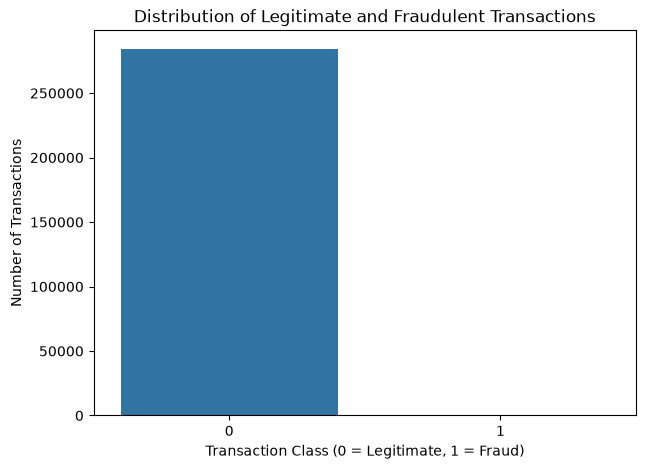

In [4]:
plt.figure(figsize=(7, 5))

sns.countplot(data=credit_df, x="Class")

plt.title("Distribution of Legitimate and Fraudulent Transactions")
plt.xlabel("Transaction Class (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Number of Transactions")

plt.show()

### 2.1 Observations

The dataset contains 284,807 credit card transactions, with 284,315 legitimate transactions and 492 fraudulent transactions.

There are no missing values in the dataset.

From the class distribution, I observed that only around 0.17% of transactions are fraudulent. This shows that the dataset is highly imbalanced.

The bar chart also shows a large difference between legitimate and fraudulent transactions.

Because of this imbalance, I will evaluate the Logistic Regression model using precision, recall, and F1-score along with accuracy.

## 3. Data Preprocessing

In this section, I will remove duplicate records and prepare the dataset for model training. I will also separate the input features from the target variable.

The numerical features will be scaled after splitting the dataset to avoid data leakage.

In [5]:
# Create a copy of the original dataset
credit_cleaned = credit_df.copy()

# Remove duplicate records
credit_cleaned = credit_cleaned.drop_duplicates()

# Display the results
print("Original Dataset Shape:", credit_df.shape)
print("Cleaned Dataset Shape:", credit_cleaned.shape)
print("Duplicates Remaining:", credit_cleaned.duplicated().sum())

# Check class distribution after cleaning
print("\nClass Distribution After Cleaning:")
print(credit_cleaned["Class"].value_counts())

Original Dataset Shape: (284807, 31)
Cleaned Dataset Shape: (283726, 31)
Duplicates Remaining: 0

Class Distribution After Cleaning:
Class
0    283253
1       473
Name: count, dtype: int64


### 3.1 Observations

I found 1,081 duplicate records and removed them from a copy of the original dataset.

After cleaning, the dataset contains 283,726 transactions, including 283,253 legitimate transactions and 473 fraudulent transactions.

There are no duplicate records remaining. The dataset is still highly imbalanced, with significantly fewer fraudulent transactions than legitimate transactions.

## 4. Train-Test Split

In this section, I will separate the input features from the target variable and split the cleaned dataset into 70% training data and 30% testing data.

I will use stratified splitting to maintain a similar proportion of legitimate and fraudulent transactions in both datasets.

In [6]:
# Separate input features and target variable
X = credit_cleaned.drop(columns=["Class"])
y = credit_cleaned["Class"]

# Split the dataset into 70% training and 30% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Display dataset dimensions
print("Training Features Shape:", X_train.shape)
print("Testing Features Shape:", X_test.shape)

print("\nTraining Class Distribution:")
print(y_train.value_counts())

print("\nTesting Class Distribution:")
print(y_test.value_counts())

Training Features Shape: (198608, 30)
Testing Features Shape: (85118, 30)

Training Class Distribution:
Class
0    198277
1       331
Name: count, dtype: int64

Testing Class Distribution:
Class
0    84976
1      142
Name: count, dtype: int64


### 4.1 Observations

I divided the cleaned dataset into 70% training data and 30% testing data.

The training dataset contains 198,608 transactions, while the testing dataset contains 85,118 transactions.

I used stratified splitting to maintain a similar proportion of fraudulent and legitimate transactions in both datasets.

## 5. Feature Scaling

In this section, I will standardize the numerical features using StandardScaler.

Feature scaling helps keep numerical values on a similar scale, which can improve Logistic Regression training.

I will fit the scaler using only the training data and apply the same transformation to the testing data to avoid data leakage.

In [7]:
# Create the StandardScaler
scaler = StandardScaler()

# Fit the scaler on training data and transform it
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing data using the same scaler
X_test_scaled = scaler.transform(X_test)

# Display the results
print("Training Data Shape After Scaling:", X_train_scaled.shape)
print("Testing Data Shape After Scaling:", X_test_scaled.shape)

# Check the mean and standard deviation of the first feature
print("\nFirst Feature Mean After Scaling:",
      round(X_train_scaled[:, 0].mean(), 4))

print("First Feature Standard Deviation After Scaling:",
      round(X_train_scaled[:, 0].std(), 4))

Training Data Shape After Scaling: (198608, 30)
Testing Data Shape After Scaling: (85118, 30)

First Feature Mean After Scaling: -0.0
First Feature Standard Deviation After Scaling: 1.0


### 5.1 Observations

I applied StandardScaler to standardize the numerical features in the dataset.

After scaling, the training dataset still contains 198,608 rows and 30 features, while the testing dataset contains 85,118 rows and 30 features.

I checked the first feature and found that its mean is approximately 0 and its standard deviation is 1. This confirms that the scaling was applied successfully.

I also fitted the scaler only on the training data and used the same scaler to transform the testing data to avoid data leakage.

## 6. Logistic Regression Model Training

In this section, I will train a Logistic Regression model using the scaled training data.

The model will learn patterns from the transaction features to classify transactions as legitimate (0) or fraudulent (1).

After training, I will use the model to make predictions on the testing dataset.

In [8]:
# Create the Logistic Regression model
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model using scaled training data
logistic_model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully!")

# Predict transaction classes using the testing data
y_pred = logistic_model.predict(X_test_scaled)

print("Predictions completed successfully!")

# Display the first 10 predictions
print("\nFirst 10 Predicted Classes:")
print(y_pred[:10])

# Display the first 10 actual classes
print("\nFirst 10 Actual Classes:")
print(y_test.iloc[:10].values)

Logistic Regression model trained successfully!
Predictions completed successfully!

First 10 Predicted Classes:
[0 0 0 0 0 0 0 0 0 0]

First 10 Actual Classes:
[0 0 0 0 0 0 0 0 0 0]


### 6.1 Observations

I successfully trained the Logistic Regression model using the scaled training dataset.

The model generated predictions for the testing dataset. When I compared the first 10 predicted values with the actual values, all 10 predictions matched.

All 10 transactions were classified as legitimate (0), which matched their actual classes.

However, these results only represent the first 10 transactions. I will evaluate the model using accuracy, precision, recall, F1-score, and a confusion matrix to understand its overall performance, especially in detecting fraudulent transactions.

## 7. Logistic Regression Model Evaluation

In this section, I will evaluate the Logistic Regression model using the testing dataset.

I will calculate accuracy, precision, recall, and F1-score to measure the model's performance.

I will also generate a confusion matrix to understand how many legitimate and fraudulent transactions were correctly or incorrectly classified.

In [9]:
# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

# Display evaluation results
print("Logistic Regression Model Evaluation")
print("------------------------------------")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")

# Display classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

# Display confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Logistic Regression Model Evaluation
------------------------------------
Accuracy:  0.9991
Precision: 0.8404
Recall:    0.5563
F1-Score:  0.6695

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     84976
           1       0.84      0.56      0.67       142

    accuracy                           1.00     85118
   macro avg       0.92      0.78      0.83     85118
weighted avg       1.00      1.00      1.00     85118


Confusion Matrix:
[[84961    15]
 [   63    79]]


### 7.1 Observations

The Logistic Regression model achieved an accuracy of 99.91%, precision of 84.04%, recall of 55.63%, and an F1-score of 66.95%.

From the confusion matrix, I observed that the model correctly classified 84,961 legitimate transactions and detected 79 fraudulent transactions.

However, it incorrectly classified 15 legitimate transactions as fraudulent and missed 63 actual fraudulent transactions.

Although the overall accuracy is very high, the recall is relatively low. This means the model is not detecting all fraudulent transactions effectively.

Since the dataset is highly imbalanced, accuracy alone does not fully represent the model's performance. Recall and F1-score provide additional information about how well the model identifies fraudulent transactions.

I think recall is especially important for this problem because the main goal is to detect fraudulent transactions. Even though the model has high accuracy, it missed 63 out of 142 fraudulent transactions in the test dataset. This means the model could allow some fraudulent transactions to go undetected. Improving recall would help detect more fraud, although it might also increase false alarms.

## 8. Confusion Matrix Visualization

In this section, I will visualize the confusion matrix to better understand the model's classification results.

The visualization will show the number of correctly and incorrectly classified legitimate and fraudulent transactions.

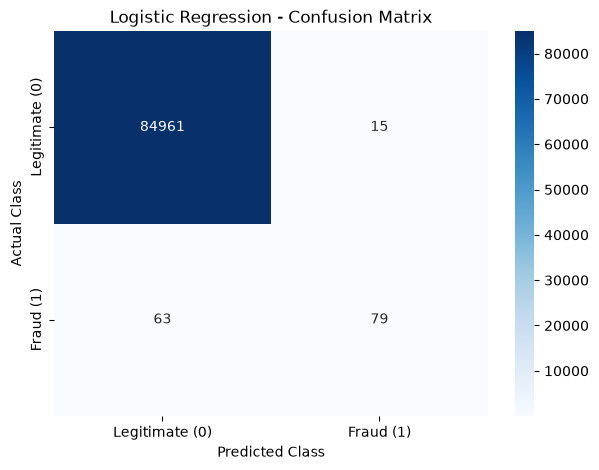

In [10]:
# Visualize the confusion matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate (0)", "Fraud (1)"],
    yticklabels=["Legitimate (0)", "Fraud (1)"]
)

plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

### 8.1 Observations

The confusion matrix visualization shows that the Logistic Regression model correctly classified 84,961 legitimate transactions and 79 fraudulent transactions.

However, the model incorrectly identified 15 legitimate transactions as fraudulent and failed to detect 63 fraudulent transactions.

The visualization shows that the model performs very well when identifying legitimate transactions but has difficulty detecting some fraudulent transactions.

This is an important limitation because detecting fraudulent transactions is the main objective of this classification task.

## 9. Conclusion

In Part A, I used the Credit Card Fraud Detection dataset to build a Logistic Regression classification model.

I explored the dataset, checked for missing values, removed duplicate records, and divided the cleaned data into 70% training and 30% testing sets. I also standardized the numerical features before training the model.

The model achieved an accuracy of 99.91%, precision of 84.04%, recall of 55.63%, and an F1-score of 66.95%.

Although the model achieved high accuracy, it missed 63 fraudulent transactions out of 142 actual fraudulent transactions in the testing dataset.

From this experiment, I learned that accuracy alone is not sufficient when evaluating a model trained on an imbalanced dataset. Recall and F1-score are also important for understanding how effectively the model detects fraudulent transactions.

Overall, the Logistic Regression model performed well in identifying legitimate transactions, but its fraud detection performance could be improved.

# Part B: Insurance Cost Prediction Using Linear Regression

## 1. Dataset Overview

**Dataset Source:** Kaggle — Medical Cost Personal Datasets  
https://www.kaggle.com/datasets/mirichoi0218/insurance

In this part, I will use the Insurance dataset to build a Linear Regression model that predicts medical insurance charges based on different personal and demographic features.

The dataset contains information such as age, sex, BMI, number of children, smoking status, region, and insurance charges.

The target variable is `charges`, which represents the medical insurance cost.

I will explore and preprocess the dataset, divide it into 70% training and 30% testing data, train a Linear Regression model, and evaluate its performance.

I used Linear Regression because the goal is to predict a numerical value rather than a category. In this case, the model uses features such as age, BMI, and smoking status to estimate insurance charges. Linear Regression learns a relationship between these input features and the insurance cost.

In [11]:
# Load the insurance dataset
insurance_df = pd.read_csv("../data/insurance.csv")

# Display the first 5 rows
print("First 5 Rows of the Insurance Dataset:")
display(insurance_df.head())

# Display dataset shape
print("\nDataset Shape:", insurance_df.shape)

# Display column names
print("\nColumn Names:")
print(insurance_df.columns.tolist())

# Display dataset information
print("\nDataset Information:")
insurance_df.info()

First 5 Rows of the Insurance Dataset:


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520



Dataset Shape: (1338, 7)

Column Names:
['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


### 1.1 Observations

The insurance dataset contains 1,338 records and 7 columns.

The dataset includes numerical features such as age, BMI, and number of children, along with categorical features such as sex, smoker, and region.

The target variable is `charges`, which represents the medical insurance cost that I will predict using Linear Regression.

All columns contain 1,338 non-null values, indicating that there are no missing values in the dataset.

## 2. Data Exploration and Quality Checks

In this section, I will check the insurance dataset for missing values and duplicate records.

I will also examine the statistical summary of numerical features and the distribution of categorical variables to better understand the dataset before preprocessing.

In [12]:
# Check missing values
print("Missing Values:")
print(insurance_df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:", insurance_df.duplicated().sum())

# Display statistical summary
print("\nStatistical Summary:")
display(insurance_df.describe())

# Examine categorical features
print("\nSex Distribution:")
print(insurance_df["sex"].value_counts())

print("\nSmoker Distribution:")
print(insurance_df["smoker"].value_counts())

print("\nRegion Distribution:")
print(insurance_df["region"].value_counts())

Missing Values:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Duplicate Records: 1

Statistical Summary:


,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010



Sex Distribution:
sex
male      676
female    662
Name: count, dtype: int64

Smoker Distribution:
smoker
no     1064
yes     274
Name: count, dtype: int64

Region Distribution:
region
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64


### 2.1 Observations

The insurance dataset contains 1,338 records with no missing values. However, I found one duplicate record.

The average age is approximately 39 years, and the average BMI is 30.66. The average insurance charge is approximately 13,270.42, with charges ranging from 1,121.87 to 63,770.43.

The dataset contains 676 males and 662 females. There are 1,064 non-smokers and 274 smokers.

The records are distributed across four regions, with the southeast having slightly more records than the other regions.

From this exploration, I observed that insurance charges vary considerably across the dataset. I will explore the relationships between the features and insurance charges before training the Linear Regression model.

## 3. Data Visualization

In this section, I will visualize the distribution of insurance charges and examine how age and smoking status relate to insurance costs.

These visualizations will help me understand the dataset before preprocessing and training the Linear Regression model.

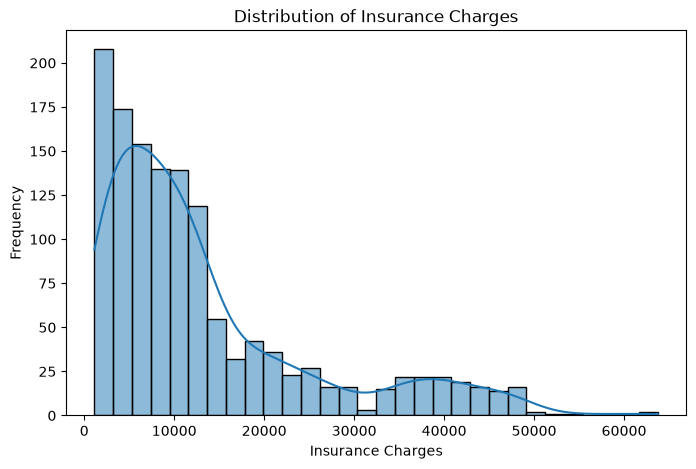

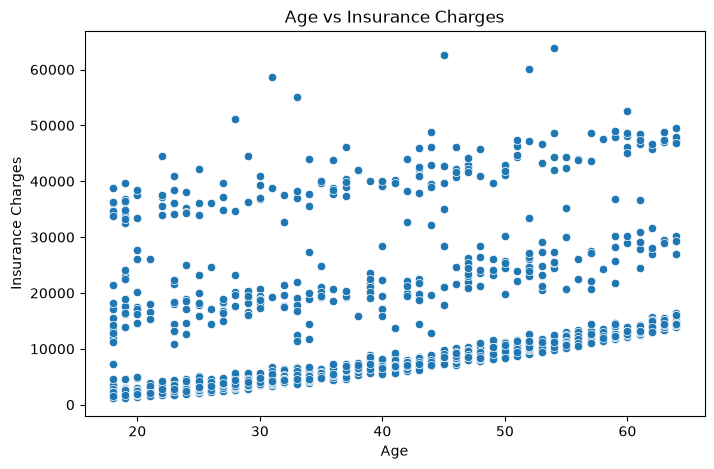

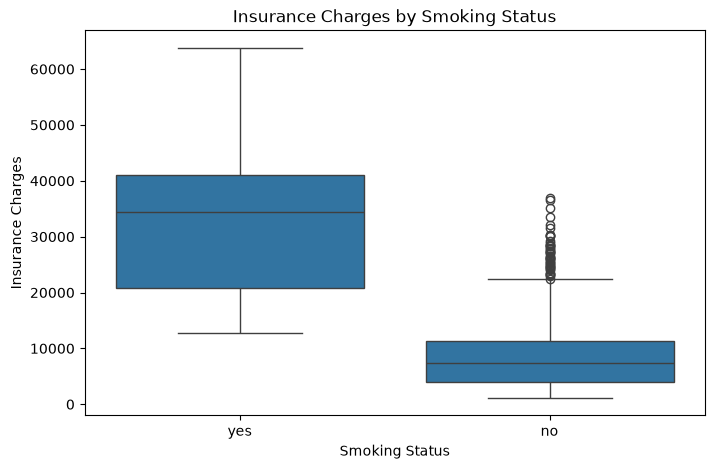

In [13]:
# 1. Distribution of insurance charges
plt.figure(figsize=(8, 5))

sns.histplot(
    data=insurance_df,
    x="charges",
    bins=30,
    kde=True
)

plt.title("Distribution of Insurance Charges")
plt.xlabel("Insurance Charges")
plt.ylabel("Frequency")
plt.show()


# 2. Age vs Insurance Charges
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=insurance_df,
    x="age",
    y="charges"
)

plt.title("Age vs Insurance Charges")
plt.xlabel("Age")
plt.ylabel("Insurance Charges")
plt.show()


# 3. Smoking Status vs Insurance Charges
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=insurance_df,
    x="smoker",
    y="charges"
)

plt.title("Insurance Charges by Smoking Status")
plt.xlabel("Smoking Status")
plt.ylabel("Insurance Charges")
plt.show()

### 3.1 Observations

From the distribution of insurance charges, I observed that most records have lower insurance costs, while fewer records have very high charges. The distribution is right-skewed.

The scatter plot shows that insurance charges generally increase with age. However, people of similar ages can have different insurance costs, indicating that other features may also influence the charges.

The box plot shows a clear difference between smokers and non-smokers. Smokers generally have much higher insurance charges, with a median of approximately 34,000 compared to around 7,000 for non-smokers.

Based on these visualizations, age and smoking status appear to be important features for predicting insurance charges.

## 4. Data Preprocessing

In this section, I will prepare the insurance dataset for Linear Regression.

I will remove the duplicate record and separate the input features from the target variable.

The dataset also contains categorical features such as sex, smoker, and region. These features will be converted into numerical values before training the model.

In [14]:
# Create a copy of the original dataset
insurance_cleaned = insurance_df.copy()

# Remove duplicate records
insurance_cleaned = insurance_cleaned.drop_duplicates()

# Display cleaning results
print("Original Dataset Shape:", insurance_df.shape)
print("Cleaned Dataset Shape:", insurance_cleaned.shape)
print("Duplicates Remaining:", insurance_cleaned.duplicated().sum())

# Separate input features and target variable
X_insurance = insurance_cleaned.drop(columns=["charges"])
y_insurance = insurance_cleaned["charges"]

print("\nInput Features Shape:", X_insurance.shape)
print("Target Variable Shape:", y_insurance.shape)

print("\nInput Features:")
print(X_insurance.columns.tolist())

print("\nTarget Variable: charges")

Original Dataset Shape: (1338, 7)
Cleaned Dataset Shape: (1337, 7)
Duplicates Remaining: 0

Input Features Shape: (1337, 6)
Target Variable Shape: (1337,)

Input Features:
['age', 'sex', 'bmi', 'children', 'smoker', 'region']

Target Variable: charges


### 4.1 Observations

I found one duplicate record in the insurance dataset and removed it during preprocessing.

After cleaning, the dataset contains 1,337 records with no remaining duplicates.

I separated the dataset into six input features and one target variable, `charges`.

The input features include age, sex, BMI, number of children, smoking status, and region.

The categorical features will be converted into numerical values before training the Linear Regression model.

## 5. Train-Test Split

In this section, I will divide the cleaned insurance dataset into 70% training data and 30% testing data.

The training dataset will be used to train the Linear Regression model, while the testing dataset will be used to evaluate its performance on unseen data.

In [15]:
# Split the insurance dataset into 70% training and 30% testing
X_insurance_train, X_insurance_test, y_insurance_train, y_insurance_test = train_test_split(
    X_insurance,
    y_insurance,
    test_size=0.30,
    random_state=42
)

# Display the dataset dimensions
print("Training Features Shape:", X_insurance_train.shape)
print("Testing Features Shape:", X_insurance_test.shape)

print("\nTraining Target Shape:", y_insurance_train.shape)
print("Testing Target Shape:", y_insurance_test.shape)

# Display the number of records
print("\nTraining Records:", len(X_insurance_train))
print("Testing Records:", len(X_insurance_test))

Training Features Shape: (935, 6)
Testing Features Shape: (402, 6)

Training Target Shape: (935,)
Testing Target Shape: (402,)

Training Records: 935
Testing Records: 402


### 5.1 Observations

I divided the cleaned insurance dataset into 70% training data and 30% testing data.

The training dataset contains 935 records, while the testing dataset contains 402 records.

Both datasets contain six input features, and the corresponding target values represent insurance charges.

I used `random_state=42` to make the split reproducible. The training data will be used to build the Linear Regression model, and the testing data will be used to evaluate its performance.

## 6. Encoding Categorical Features

In this section, I will convert the categorical features into numerical values using One-Hot Encoding.

The categorical features are sex, smoker, and region.

I will fit the encoder using only the training data and apply the same transformation to the testing data to avoid data leakage.

In [16]:
# Identify categorical and numerical features
categorical_features = ["sex", "smoker", "region"]
numerical_features = ["age", "bmi", "children"]

# Create a ColumnTransformer for preprocessing
insurance_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(drop="first", handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            "passthrough",
            numerical_features
        )
    ]
)

# Fit the encoder on training data
X_insurance_train_encoded = insurance_preprocessor.fit_transform(
    X_insurance_train
)

# Apply the same transformation to testing data
X_insurance_test_encoded = insurance_preprocessor.transform(
    X_insurance_test
)

# Display the results
print("Training Data Shape After Encoding:",
      X_insurance_train_encoded.shape)

print("Testing Data Shape After Encoding:",
      X_insurance_test_encoded.shape)

# Display transformed feature names
print("\nEncoded Feature Names:")
print(insurance_preprocessor.get_feature_names_out())

Training Data Shape After Encoding: (935, 8)
Testing Data Shape After Encoding: (402, 8)

Encoded Feature Names:
['categorical__sex_male' 'categorical__smoker_yes'
 'categorical__region_northwest' 'categorical__region_southeast'
 'categorical__region_southwest' 'numerical__age' 'numerical__bmi'
 'numerical__children']


### 6.1 Observations

I applied One-Hot Encoding to convert the categorical features (`sex`, `smoker`, and `region`) into numerical values.

After encoding, the number of input features increased from 6 to 8.

The training dataset contains 935 records with 8 features, while the testing dataset contains 402 records with 8 features.

I used `drop="first"` to avoid creating redundant columns for each categorical feature.

I fitted the encoder using only the training data and applied the same transformation to the testing data to avoid data leakage.

The dataset is now ready for Linear Regression model training.

## 7. Linear Regression Model Training

In this section, I will train a Linear Regression model using the preprocessed insurance dataset.

The model will learn the relationship between the input features and insurance charges.

After training, I will use the model to predict insurance charges for the testing dataset.

In [17]:
# Create the Linear Regression model
linear_model = LinearRegression()

# Train the model
linear_model.fit(
    X_insurance_train_encoded,
    y_insurance_train
)

print("Linear Regression model trained successfully!")

# Predict insurance charges using testing data
y_insurance_pred = linear_model.predict(
    X_insurance_test_encoded
)

print("Predictions completed successfully!")

# Compare the first 10 actual and predicted insurance charges
comparison_df = pd.DataFrame({
    "Actual Charges": y_insurance_test.iloc[:10].values,
    "Predicted Charges": y_insurance_pred[:10]
})

print("\nFirst 10 Actual vs Predicted Insurance Charges:")
display(comparison_df.round(2))

Linear Regression model trained successfully!
Predictions completed successfully!

First 10 Actual vs Predicted Insurance Charges:


,Actual Charges,Predicted Charges
0,8688.86,8075.92
1,5708.87,5499.00
2,11436.74,14345.71
3,38746.36,31428.20
4,4463.21,8874.78
5,9304.70,13108.24
6,38511.63,30222.45
7,2150.47,1224.76
8,7345.73,10576.43
9,10264.44,11204.40


### 7.1 Observations

I successfully trained the Linear Regression model using the encoded training dataset.

The model generated insurance charge predictions for the testing dataset.

When I compared the first 10 predicted charges with the actual charges, I observed that some predictions were close to the actual values, while others had larger differences.

For example, the model predicted 8,075.92 for an actual charge of 8,688.86, which is relatively close. However, for an actual charge of 38,746.36, the model predicted 31,428.20.

These results show that the model can estimate insurance charges, but the predictions are not always accurate.

I will evaluate the model using MAE, RMSE, and R² to measure its overall performance.

## 8. Linear Regression Model Evaluation

In this section, I will evaluate the Linear Regression model using the testing dataset.

I will calculate Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R-squared (R²) to measure the model's prediction performance.

These metrics will help me understand the average prediction error and how well the model explains variations in insurance charges.

In [18]:
# Calculate evaluation metrics
insurance_mae = mean_absolute_error(
    y_insurance_test,
    y_insurance_pred
)

insurance_rmse = np.sqrt(
    mean_squared_error(
        y_insurance_test,
        y_insurance_pred
    )
)

insurance_r2 = r2_score(
    y_insurance_test,
    y_insurance_pred
)

# Display evaluation results
print("Linear Regression Model Evaluation")
print("----------------------------------")
print(f"Mean Absolute Error (MAE): {insurance_mae:.2f}")
print(f"Root Mean Squared Error (RMSE): {insurance_rmse:.2f}")
print(f"R-Squared (R²): {insurance_r2:.4f}")

Linear Regression Model Evaluation
----------------------------------
Mean Absolute Error (MAE): 4181.82
Root Mean Squared Error (RMSE): 6240.21
R-Squared (R²): 0.7724


### 8.1 Observations

The Linear Regression model achieved a Mean Absolute Error (MAE) of 4,181.82, a Root Mean Squared Error (RMSE) of 6,240.21, and an R² score of 0.7724.

The MAE indicates that the predicted insurance charges differ from the actual charges by approximately 4,181.82 on average.

The RMSE is higher than the MAE, which suggests that some predictions have larger errors.

The R² score indicates that the model explains approximately 77.24% of the variation in insurance charges in the testing dataset.

Overall, the model explains a substantial portion of the variation in insurance charges, but there is still room to improve its prediction accuracy.

## 9. Actual vs Predicted Insurance Charges

In this section, I will compare the actual insurance charges with the values predicted by the Linear Regression model.

I will use a scatter plot to visualize the prediction results and identify differences between actual and predicted charges.

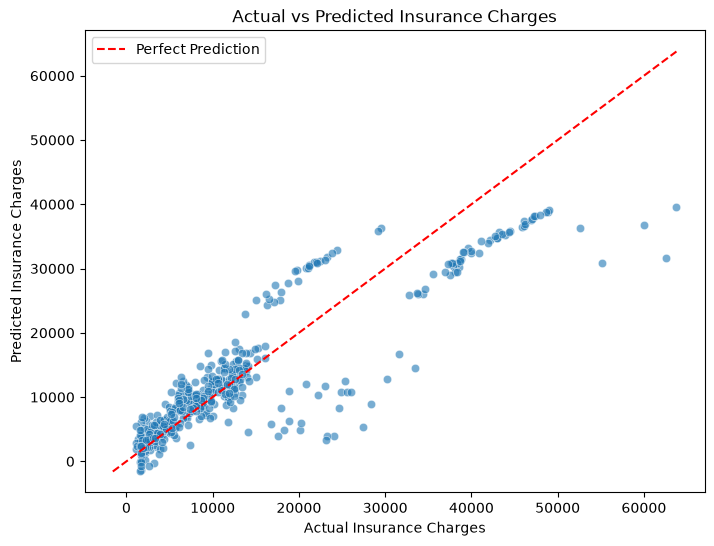

In [19]:
# Plot actual vs predicted insurance charges
plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=y_insurance_test,
    y=y_insurance_pred,
    alpha=0.6
)

# Add a reference line for perfect predictions
min_value = min(y_insurance_test.min(), y_insurance_pred.min())
max_value = max(y_insurance_test.max(), y_insurance_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    color="red",
    linestyle="--",
    label="Perfect Prediction"
)

plt.title("Actual vs Predicted Insurance Charges")
plt.xlabel("Actual Insurance Charges")
plt.ylabel("Predicted Insurance Charges")
plt.legend()
plt.show()

### 9.1 Observations

The scatter plot compares the actual insurance charges with the values predicted by the Linear Regression model.

I observed that many predictions for lower insurance charges are relatively close to the red dashed line, indicating smaller prediction errors.

However, several predictions for higher insurance charges are farther from the line, showing that the model has difficulty predicting some expensive insurance cases accurately.

Some points are above the line, indicating overprediction, while others are below the line, indicating underprediction.

Overall, the graph shows that the model can predict insurance charges reasonably well for many records, but some predictions have considerable errors.

## 10. Conclusion

In Part B, I used the Insurance dataset to build a Linear Regression model for predicting medical insurance charges.

I explored the dataset, checked for missing values, removed one duplicate record, and visualized the relationships between different features and insurance charges.

After preprocessing, I divided the cleaned dataset into 70% training data and 30% testing data. I also applied One-Hot Encoding to convert categorical features into numerical values before training the model.

The Linear Regression model achieved a Mean Absolute Error (MAE) of 4,181.82, a Root Mean Squared Error (RMSE) of 6,240.21, and an R² score of 0.7724.

The R² score indicates that the model explains approximately 77.24% of the variation in insurance charges in the testing dataset.

From the actual vs predicted visualization, I observed that the model performed reasonably well for many lower insurance charges but showed larger errors for some higher charges.

Overall, the Linear Regression model provided useful predictions, although its performance could be improved to reduce prediction errors.